In [1]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.insert(0, '/content/drive/MyDrive/predictive_learning')

import networks
from networks import LateralInhibitoryLayer
import generators
from generators import MovingMNIST32
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output


def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))


Mounted at /content/drive


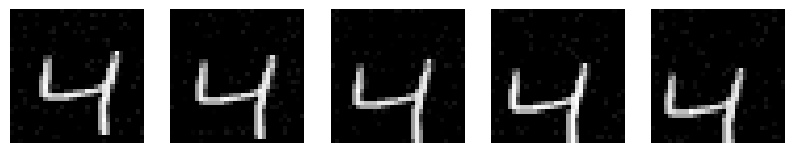

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

vg_params = MovingMNIST32.default_params()
mnist_path = Path("/tmp/mnist.npz")
if not mnist_path.exists():
    urlretrieve(
        "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
        mnist_path,
    )

data = np.load(mnist_path)

images = data["x_train"].reshape(data["x_train"].shape[0], -1)
labels = data["y_train"]
mnist_csv_path = Path("/tmp/mnist_train.csv")

if not mnist_csv_path.exists():
    header = ",".join(["label"] + [f"pixel{i}" for i in range(images.shape[1])])
    np.savetxt(
        mnist_csv_path,
        np.column_stack((labels, images)),
        delimiter=",",
        header=header,
        comments="",
        fmt="%d",
    )

vg = MovingMNIST32(file=str(mnist_csv_path))
vg.set_random_position()
vg.set_random_position()


#add 5 columns and 1 row in a grid of subplots
figure, ax = plt.subplots(1, 5, figsize=(10, 15))
for i in range(5):
    vg.set_next_position()
    ax[i].imshow(vg.get_current_frame().reshape(vg.x_size, vg.y_size), cmap='gray')
    ax[i].axis('off')

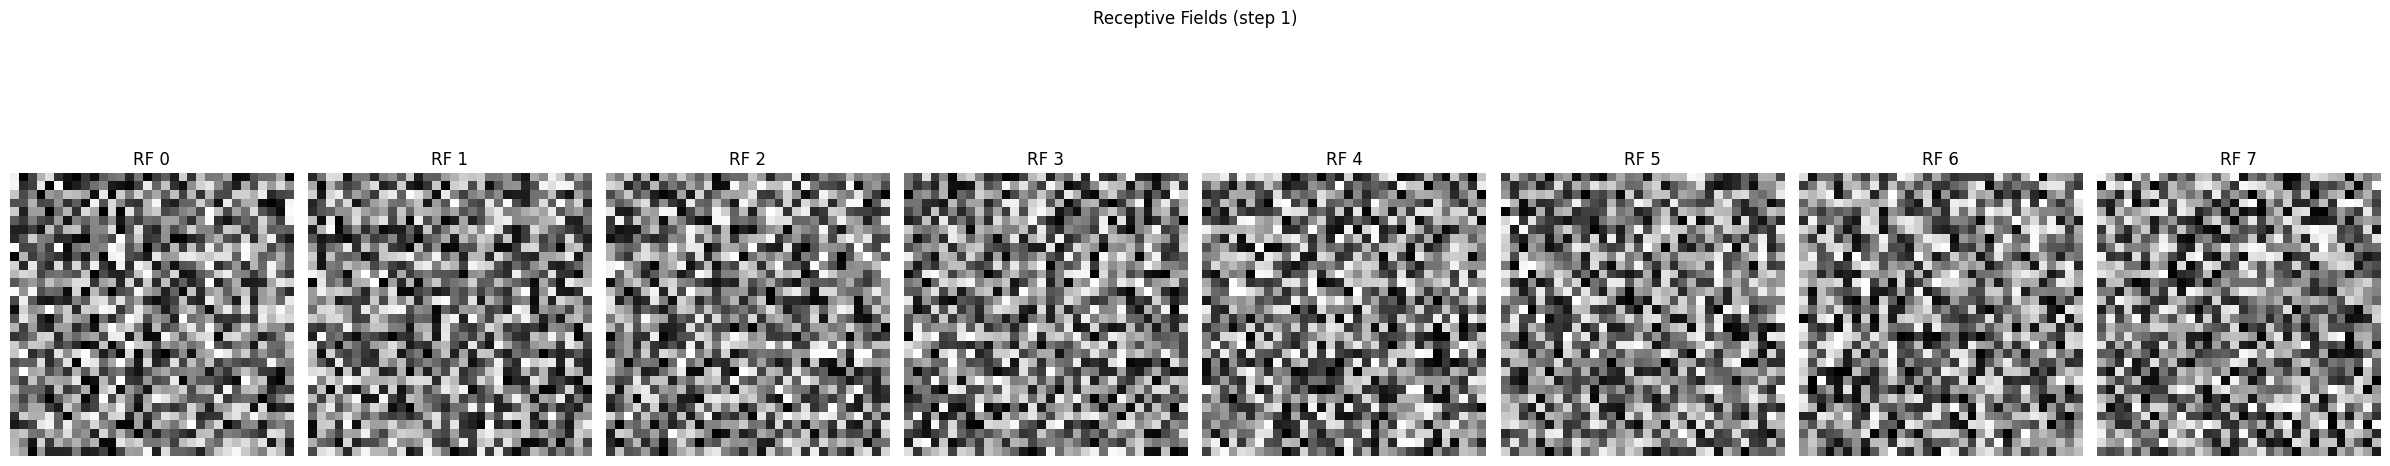

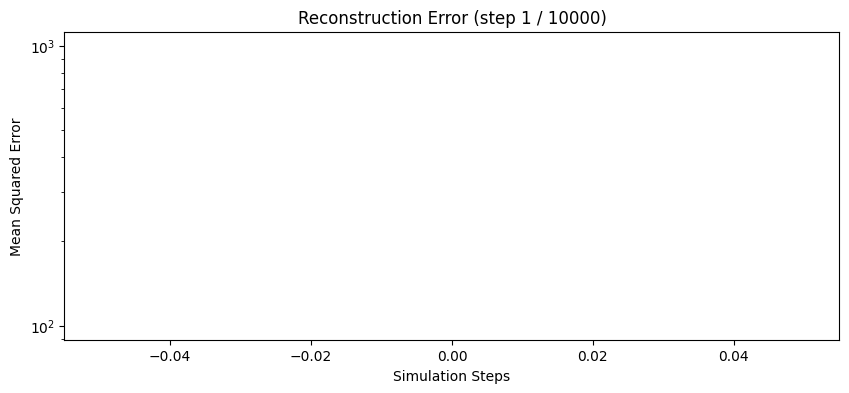

In [ ]:
#select hyperparameters for the simulation
num_steps = 10000
sequence_size = 10
num_tests = 10

#create a linear network with 50 units and change the w_rule rule accordingly (hebbian, bcm_abs, perceptron)
network_params = LateralInhibitoryLayer.default_hparams(vg.get_shape())
network_params['activation'] = 'relu'
network_params['num_units_y'] = 500
network_params['gradient'] = 'voltage'
network_params['w_update'] = 'perceptron'
network_params['w_rectify'] = True
network_params['w_seed'] = 42
network_params['w_init'] = 'random'
network_params['w_lr'] = 0.001
network_params['m_update'] = 'hebbian'
network_params['m_rectify'] = False
network_params['m_init'] = 'random'
network_params['m_lr'] = 0.001
network_params['p_update'] = 'perceptron'
network_params['p_rectify'] = True
network_params['p_init'] = 'random'
network_params['p_lr'] = 0.001
network_params['num_steps'] = 500
network_params['step'] = 0.01
network_params['normalize_w_weights'] = True
network_params['normalize_p_weights'] = True

network = LateralInhibitoryLayer(network_params)
#save results
synaptic_input_distance_from_identity_perceptron = []
distance_from_identity_perceptron = []
consistency_error_perceptron = []
second_moment_estimate_perceptron = []
mse_error_perceptron = []

fig, ax = plt.subplots(figsize=(10, 4))

#network.lr_w = 0.0005
#network.lr_m = 0.001
for i in range(num_steps):
    if i % 1000 == 0:
        print(f"Iteration {i}")
        examples = []
        examples_input = []
        errors = []
        for j in range(num_tests):
            vg.set_random_position()
            network.reset_network()
            for sequence_step in range(sequence_size//2):
                vg.set_next_position()
                x = vg.get_current_frame().flatten()
                network.new_epoch()
                network.update_activations(x, False)
                examples.append(network.y.copy())
                errors.append(np.linalg.norm((x - network.projection()).reshape(1,-1), ord=2))
                examples_input.append(network.w @ x)
            for sequence_step in range(sequence_size//2, sequence_size):
                vg.set_next_position()
                x = vg.get_blind_frame().flatten()
                network.new_epoch()
                network.update_activations(x, False)
                examples.append(network.y.copy())
                errors.append(np.linalg.norm((x - network.projection()).reshape(1,-1), ord=2))
                examples_input.append(network.w @ x)
        synaptic_input_distance_from_identity_perceptron.append(np.linalg.norm(np.cov(np.array(examples_input), rowvar=False) - np.eye(network.m.shape[0]), ord='fro'))
        current_second_moment_estimate = np.cov(np.array(examples), rowvar=False)
        distance_from_identity_perceptron.append(np.linalg.norm(network.m - np.eye(network.m.shape[0]), ord='fro'))
        consistency_error_perceptron.append(np.linalg.norm((network.w @ network.w.T) - (current_second_moment_estimate), ord='fro'))
        second_moment_estimate_perceptron.append(np.linalg.norm(current_second_moment_estimate - np.eye(network.m.shape[0]), ord='fro'))
        mse_error_perceptron.append(np.mean(errors))
        clear_output(wait=True)
        ax.cla()
        ax.semilogy(np.array(mse_error_perceptron), alpha=0.8, color='steelblue')
        ax.set_title(f"Reconstruction Error (step {i + 1} / {num_steps})")
        ax.set_xlabel("Simulation Steps")
        ax.set_ylabel("Mean Squared Error")
        # Plot a few receptive fields during training
        num_show = min(8, network.w.shape[0])
        fig_rf, rf_axes = plt.subplots(1, num_show, figsize=(3 * num_show, 6))
        if num_show == 1:
            rf_axes = [rf_axes]

        sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]  # Sort by norm of weights
        for j in range(num_show):
            rf_img = network.w[sorted_indices[j]].reshape(vg.x_size, vg.y_size)
            vmax = np.max(np.abs(rf_img))
            rf_axes[j].imshow(rf_img, cmap='gray', vmin=0, vmax=vmax)
            rf_axes[j].set_title(f"RF {j}")
            rf_axes[j].axis("off")

        fig_rf.suptitle(f"Receptive Fields (step {i + 1})")
        plt.tight_layout()
        display(fig_rf)
        plt.close(fig_rf)
        display(fig)

    vg.set_random_position()
    network.reset_network()
    for sequence_step in range(5):
        vg.set_next_position()
        x = vg.get_current_frame().flatten()
        network.new_epoch()
        network.update_activations(x, True)
        network.update_parameters(['m', 'w', 'p'])


plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

plt.plot(distance_from_identity_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Distance from Identity')
plt.show()

plt.plot(consistency_error_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Consistency Error')
plt.show()

plt.plot(second_moment_estimate_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Output distance from Identity')
plt.show()

plt.plot(mse_error_perceptron)
plt.xlabel('Iterations')
plt.ylabel('MSE Error')
plt.show()

In [ ]:
#select hyperparameters for the simulation
num_steps = 10000
sequence_size = 10
num_tests = 10

#create a linear network with 50 units and change the w_rule rule accordingly (hebbian, bcm_abs, perceptron)
network_params = LateralInhibitoryLayer.default_hparams(vg.get_shape())
network_params['activation'] = 'relu'
network_params['num_units_y'] = 250
network_params['gradient'] = 'voltage'
network_params['w_update'] = 'perceptron'
network_params['w_rectify'] = True
network_params['w_seed'] = 42
network_params['w_init'] = 'random'
network_params['w_dynamic'] = True
network_params['m_update'] = 'hebbian'
network_params['m_rectify'] = False
network_params['m_init'] = 'random'
network_params['m_dynamic'] = True
network_params['p_update'] = 'perceptron'
network_params['p_rectify'] = True
network_params['p_init'] = 'random'
network_params['p_dynamic'] = True
network_params['num_steps'] = 1500
network_params['step'] = 0.01
network_params['normalize_w_weights'] = True
network_params['normalize_p_weights'] = True

network = LateralInhibitoryLayer(network_params)
#save results
synaptic_input_distance_from_identity_perceptron = []
distance_from_identity_perceptron = []
consistency_error_perceptron = []
second_moment_estimate_perceptron = []
mse_error_perceptron = []

fig, ax = plt.subplots(figsize=(10, 4))

#network.lr_w = 0.0005
#network.lr_m = 0.001
for i in range(num_steps):
    if i % 1000 == 0:
        print(f"Iteration {i}")
        examples = []
        examples_input = []
        errors = []
        for j in range(num_tests):
            vg.set_random_position()
            network.reset_network()
            for sequence_step in range(sequence_size//2):
                vg.set_next_position()
                x = vg.get_current_frame().flatten()
                network.new_epoch()
                network.update_activations(x, False)
                examples.append(network.y.copy())
                errors.append(np.linalg.norm((x - network.projection()).reshape(1,-1), ord=2))
                examples_input.append(network.w @ x)
            for sequence_step in range(sequence_size//2, sequence_size):
                vg.set_next_position()
                x = vg.get_blind_frame().flatten()
                network.new_epoch()
                network.update_activations(x, False)
                examples.append(network.y.copy())
                errors.append(np.linalg.norm((x - network.projection()).reshape(1,-1), ord=2))
                examples_input.append(network.w @ x)
        synaptic_input_distance_from_identity_perceptron.append(np.linalg.norm(np.cov(np.array(examples_input), rowvar=False) - np.eye(network.m.shape[0]), ord='fro'))
        current_second_moment_estimate = np.cov(np.array(examples), rowvar=False)
        distance_from_identity_perceptron.append(np.linalg.norm(network.m - np.eye(network.m.shape[0]), ord='fro'))
        consistency_error_perceptron.append(np.linalg.norm((network.w @ network.w.T) - (current_second_moment_estimate), ord='fro'))
        second_moment_estimate_perceptron.append(np.linalg.norm(current_second_moment_estimate - np.eye(network.m.shape[0]), ord='fro'))
        mse_error_perceptron.append(np.mean(errors))
        clear_output(wait=True)
        ax.cla()
        ax.semilogy(np.array(mse_error_perceptron), alpha=0.8, color='steelblue')
        ax.set_title(f"Reconstruction Error (step {i + 1} / {num_steps})")
        ax.set_xlabel("Simulation Steps")
        ax.set_ylabel("Mean Squared Error")
        # Plot a few receptive fields during training
        num_show = min(8, network.w.shape[0])
        fig_rf, rf_axes = plt.subplots(1, num_show, figsize=(3 * num_show, 6))
        if num_show == 1:
            rf_axes = [rf_axes]

        sorted_indices = np.flip(np.argsort(np.linalg.norm(network.w, axis=1)))[::-1]  # Sort by norm of weights
        for j in range(num_show):
            rf_img = network.w[sorted_indices[j]].reshape(vg.x_size, vg.y_size)
            vmax = np.max(np.abs(rf_img))
            rf_axes[j].imshow(rf_img, cmap='gray', vmin=0, vmax=vmax)
            rf_axes[j].set_title(f"RF {j}")
            rf_axes[j].axis("off")

        fig_rf.suptitle(f"Receptive Fields (step {i + 1})")
        plt.tight_layout()
        display(fig_rf)
        plt.close(fig_rf)
        display(fig)

    vg.set_random_position()
    network.reset_network()
    for sequence_step in range(5):
        vg.set_next_position()
        x = vg.get_current_frame().flatten()
        network.new_epoch()
        network.update_activations(x, True)
        network.update_parameters(['m', 'w', 'p'])


plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

plt.plot(distance_from_identity_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Distance from Identity')
plt.show()

plt.plot(consistency_error_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Consistency Error')
plt.show()

plt.plot(second_moment_estimate_perceptron)
plt.xlabel('Iterations')
plt.ylabel('Output distance from Identity')
plt.show()

plt.plot(mse_error_perceptron)
plt.xlabel('Iterations')
plt.ylabel('MSE Error')
plt.show()